# AICL 407: Reinforcement Learning
## Lab 1 — Tabular Q-Learning and SARSA on FrozenLake (8×8)
**Student Name:** Sijan Pandey  
**Roll No:** 11  
**Program:** B.Tech in Artificial Intelligence (8th Semester)  
**Course:** Advanced Intelligent Computing & Learning (AICL 407)  
**Topic:** Model-Free Tabular Temporal Difference Control  
**Benchmark:** Gymnasium `FrozenLake-v1` (`map_name='8x8'`, `is_slippery=True`)  
**Permitted Libraries:** `numpy`, `matplotlib`, `gymnasium`

---

### 1. Overview & Objectives
In this laboratory, we implement model-free tabular reinforcement learning algorithms from scratch and analyze their empirical convergence characteristics on **FrozenLake**, one of the most widely studied benchmarks in reinforcement learning.

#### Core Tasks:
* **Task 1 — $\epsilon$-Greedy Policy (10 pts):** Action selection with strictly uniform random tie-breaking.
* **Task 2 — Q-Learning Update (15 pts):** Off-policy temporal difference update with zero terminal bootstrapping. Verified to $10^{-8}$ against hand calculation.
* **Task 3 — SARSA Update (10 pts):** On-policy temporal difference update with zero terminal bootstrapping. Verified to $10^{-8}$.
* **Task 4 — Training Loop (25 pts):** Linear $\epsilon$-decay training reaching success rate $\ge 0.70$ over the last 1,000 episodes on slippery $8\times 8$ lake with seed 0.
* **Task 5 — Experiments & Report (40 pts):** Comprehensive ablations, learning curves, hyperparameter sensitivity, state value heatmaps, and policy flow fields.

---

### 2. Environment Dynamics: FrozenLake (8×8 Slippery)
* **State Space:** $|\mathcal{S}| = 64$ discrete states (tiles numbered 0 to 63 from top-left to bottom-right).
* **Action Space:** $|\mathcal{A}| = 4$ discrete actions: `0: LEFT`, `1: DOWN`, `2: RIGHT`, `3: UP`.
* **Slippery Dynamics:** With probability $1/3$, the agent moves in the intended direction; with probability $1/3$, it slips in each perpendicular direction.
* **Reward Structure:** $+1.0$ on reaching the Goal tile (`G`, state 63); $0.0$ everywhere else, including Holes (`H`).
* **Termination:** Episode ends immediately upon reaching Goal (`G`) or falling into a Hole (`H`).


---
### 3. Mathematical Foundations: Bellman Equations & TD Control

#### Markov Decision Process (MDP)
Defined by the tuple $\langle \mathcal{S}, \mathcal{A}, \mathcal{P}, \mathcal{R}, \gamma \rangle$ where $\gamma \in [0, 1)$ is the discount factor.

#### Bellman Optimality Equation
$$Q^*(s, a) = \sum_{s'} \mathcal{P}(s' \mid s, a) \left[ \mathcal{R}(s, a, s') + \gamma \max_{a'} Q^*(s', a') \right]$$

#### Q-Learning Update Rule (Off-Policy TD Control)
$$Q(S_t, A_t) \leftarrow Q(S_t, A_t) + \alpha \left[ R_{t+1} + \gamma (1 - d_t) \max_{a'} Q(S_{t+1}, a') - Q(S_t, A_t) \right]$$
where $d_t = 1$ if $S_{t+1}$ is terminal, and $0$ otherwise.

#### SARSA Update Rule (On-Policy TD Control)
$$Q(S_t, A_t) \leftarrow Q(S_t, A_t) + \alpha \left[ R_{t+1} + \gamma (1 - d_t) Q(S_{t+1}, A_{t+1}) - Q(S_t, A_t) \right]$$
where $A_{t+1} \sim \pi(\cdot \mid S_{t+1})$ is the actual next action taken.


In [1]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.size": 10,
    "font.family": "serif",
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "figure.dpi": 150,
})

print("Gymnasium Version:", gym.__version__)
print("NumPy Version:", np.__version__)


Gymnasium Version: 1.2.3
NumPy Version: 1.24.3


---
## Task 1 — $\epsilon$-Greedy Policy with Uniform Random Tie-Breaking (10 pts)
Selects a random action with probability $\epsilon$, and the greedy action $\arg\max_a Q(s, a)$ otherwise.
**Uniform Random Tie-Breaking:** When multiple actions have the same maximal value, the choice must be uniformly random.


In [2]:
def epsilon_greedy_policy(
    Q: np.ndarray,
    state: int,
    epsilon: float,
    n_actions: int = None,
    rng: np.random.Generator = None,
) -> int:
    """Select action using epsilon-greedy policy with uniform random tie-breaking."""
    if isinstance(state, np.ndarray) and isinstance(Q, (int, np.integer)):
        Q, state = state, int(Q)

    if rng is None:
        rng = np.random.default_rng()

    q_s = Q if np.ndim(Q) == 1 else Q[state]
    num_actions = len(q_s) if n_actions is None else n_actions

    if rng.random() < epsilon:
        return int(rng.integers(0, num_actions))
    else:
        max_val = np.max(q_s)
        best_actions = np.flatnonzero(q_s == max_val)
        return int(rng.choice(best_actions))

epsilon_greedy = epsilon_greedy_policy


In [3]:
# Verification: Task 1 Tie-Breaking Uniformity
print("Running Task 1 Tie-Breaking Test...")
Q_test = np.array([[1.0, 5.0, 5.0, 2.0]], dtype=np.float64)  # Actions 1 & 2 are tied
counts = {1: 0, 2: 0}
rng_test = np.random.default_rng(42)

for _ in range(20000):
    a = epsilon_greedy_policy(Q_test, 0, epsilon=0.0, rng=rng_test)
    counts[a] = counts.get(a, 0) + 1

r1, r2 = counts[1] / 20000, counts[2] / 20000
print(f"Action 1 frequency: {r1:.4f}, Action 2 frequency: {r2:.4f}")
assert np.isclose(r1, 0.50, atol=0.02)
assert np.isclose(r2, 0.50, atol=0.02)
print(">>> [PASSED] Task 1: Tie-breaking is uniformly random.")


Running Task 1 Tie-Breaking Test...


Action 1 frequency: 0.4997, Action 2 frequency: 0.5003


>>> [PASSED] Task 1: Tie-breaking is uniformly random.


---
## Task 2 — Q-Learning Update (15 pts)
Off-policy TD update with zero bootstrap on terminal states.
$$Q(s, a) \leftarrow Q(s, a) + \alpha \left[ r + \gamma (1 - d) \max_{a'} Q(s', a') - Q(s, a) \right]$$


In [4]:
def q_learning_update(
    Q: np.ndarray,
    s: int,
    a: int,
    r: float,
    s_next: int,
    done: bool,
    alpha: float,
    gamma: float,
) -> float:
    """Off-policy Q-learning Temporal Difference update with zero terminal bootstrap."""
    target = r if done else (r + gamma * np.max(Q[s_next]))
    td_error = target - Q[s, a]
    Q[s, a] += alpha * td_error
    return float(Q[s, a])


In [5]:
# Verification: Task 2 Hand-Computed Trajectory (Precision: 1e-8)
print("Running Task 2 Hand-Computed Trajectory Test...")
Q_hand = np.zeros((3, 2), dtype=np.float64)
alpha, gamma = 0.5, 0.9

# Step 1: s=0, a=1, r=1.0, s'=1, done=False
q_learning_update(Q_hand, 0, 1, 1.0, 1, False, alpha, gamma)
assert np.isclose(Q_hand[0, 1], 0.5, atol=1e-8)

# Step 2: s=1, a=0, r=2.0, s'=2, done=False
q_learning_update(Q_hand, 1, 0, 2.0, 2, False, alpha, gamma)
assert np.isclose(Q_hand[1, 0], 1.0, atol=1e-8)

# Step 3: s=0, a=1, r=0.0, s'=1, done=False
q_learning_update(Q_hand, 0, 1, 0.0, 1, False, alpha, gamma)
assert np.isclose(Q_hand[0, 1], 0.7, atol=1e-8)

# Step 4: Terminal state: s=1, a=0, r=5.0, s'=2, done=True (Zero Bootstrap)
q_learning_update(Q_hand, 1, 0, 5.0, 2, True, alpha, gamma)
assert np.isclose(Q_hand[1, 0], 3.0, atol=1e-8)

print(">>> [PASSED] Task 2: Hand-computed trajectory verified to 1e-8 precision.")


Running Task 2 Hand-Computed Trajectory Test...
>>> [PASSED] Task 2: Hand-computed trajectory verified to 1e-8 precision.


---
## Task 3 — SARSA Update (10 pts)
On-policy TD update using actual next action $a'$ chosen by behavioral policy.
$$Q(s, a) \leftarrow Q(s, a) + \alpha \left[ r + \gamma (1 - d) Q(s', a') - Q(s, a) \right]$$


In [6]:
def sarsa_update(
    Q: np.ndarray,
    s: int,
    a: int,
    r: float,
    s_next: int,
    a_next: int,
    done: bool,
    alpha: float,
    gamma: float,
) -> float:
    """On-policy SARSA Temporal Difference update with zero terminal bootstrap."""
    target = r if done else (r + gamma * Q[s_next, a_next])
    td_error = target - Q[s, a]
    Q[s, a] += alpha * td_error
    return float(Q[s, a])


In [7]:
# Verification: Task 3 SARSA Trajectory (Precision: 1e-8)
print("Running Task 3 SARSA Verification...")
Q_sarsa = np.zeros((3, 2), dtype=np.float64)

sarsa_update(Q_sarsa, 0, 0, 1.0, 1, 1, False, 0.5, 0.9)
assert np.isclose(Q_sarsa[0, 0], 0.5, atol=1e-8)

Q_sarsa[1, 1] = 2.0
sarsa_update(Q_sarsa, 0, 0, 0.0, 1, 1, False, 0.5, 0.9)
assert np.isclose(Q_sarsa[0, 0], 1.15, atol=1e-8)

sarsa_update(Q_sarsa, 1, 1, 3.0, 2, 0, True, 0.5, 0.9)
assert np.isclose(Q_sarsa[1, 1], 2.5, atol=1e-8)

print(">>> [PASSED] Task 3: SARSA update verified to 1e-8 precision.")


Running Task 3 SARSA Verification...
>>> [PASSED] Task 3: SARSA update verified to 1e-8 precision.


---
## Task 4 — Training Loop with Linear $\epsilon$-Decay (25 pts)
Executes episodic training, applies linear $\epsilon$-decay, tracks episodic returns, step lengths, and periodic snapshots.
**Benchmark Goal:** Seed 0 must achieve success rate $\ge 0.70$ over the last 1,000 episodes on slippery $8\times 8$ lake.


In [8]:
from typing import Dict, Tuple, Optional

def train(
    env: Optional[gym.Env] = None,
    num_episodes: int = 20000,
    alpha: float = 0.1,
    gamma: float = 0.99,
    eps_start: float = 1.0,
    eps_end: float = 0.01,
    eps_decay_episodes: Optional[int] = None,
    algorithm: str = "q_learning",
    seed: int = 0,
    snapshot_interval: int = 1000,
) -> Tuple[np.ndarray, np.ndarray, np.ndarray, Dict[int, np.ndarray]]:
    """Train tabular agent using Q-learning or SARSA on FrozenLake with linear epsilon decay."""
    if env is None:
        env = gym.make("FrozenLake-v1", map_name="8x8", is_slippery=True, max_episode_steps=200)
    else:
        if hasattr(env, "_max_episode_steps") and env._max_episode_steps < 200:
            env._max_episode_steps = 200

    rng = np.random.default_rng(seed)
    n_states = env.observation_space.n
    n_actions = env.action_space.n
    Q = np.zeros((n_states, n_actions), dtype=np.float64)

    if eps_decay_episodes is None:
        eps_decay_episodes = int(num_episodes * 0.75)

    episodic_returns = np.zeros(num_episodes, dtype=np.float64)
    episode_lengths = np.zeros(num_episodes, dtype=np.int32)
    q_snapshots: Dict[int, np.ndarray] = {0: Q.copy()}

    s, _ = env.reset(seed=seed)

    for ep in range(num_episodes):
        if ep > 0:
            s, _ = env.reset()

        if ep < eps_decay_episodes:
            eps = eps_start - (eps_start - eps_end) * (ep / eps_decay_episodes)
        else:
            eps = eps_end

        done = False
        ep_ret = 0.0
        steps = 0

        if algorithm.lower() == "sarsa":
            a = epsilon_greedy_policy(Q, s, eps, n_actions, rng)
            while not done:
                s_next, r, terminated, truncated, _ = env.step(a)
                done = terminated or truncated
                steps += 1
                ep_ret += r
                a_next = epsilon_greedy_policy(Q, s_next, eps, n_actions, rng) if not done else 0
                sarsa_update(Q, s, a, r, s_next, a_next, terminated, alpha, gamma)
                s, a = s_next, a_next
        else:  # Q-learning
            while not done:
                a = epsilon_greedy_policy(Q, s, eps, n_actions, rng)
                s_next, r, terminated, truncated, _ = env.step(a)
                done = terminated or truncated
                steps += 1
                ep_ret += r
                q_learning_update(Q, s, a, r, s_next, terminated, alpha, gamma)
                s = s_next

        episodic_returns[ep] = ep_ret
        episode_lengths[ep] = steps

        if (ep + 1) % snapshot_interval == 0:
            q_snapshots[ep + 1] = Q.copy()

    return Q, episodic_returns, episode_lengths, q_snapshots


In [9]:
# Verification: Task 4 Benchmark on 8x8 Slippery FrozenLake (Seed 0)
print("Training Q-learning agent on FrozenLake 8x8 slippery with Seed 0...")
Q_final, returns, lengths, snapshots = train(
    num_episodes=20000,
    alpha=0.1,
    gamma=0.99,
    eps_start=1.0,
    eps_end=0.01,
    eps_decay_episodes=15000,
    algorithm="q_learning",
    seed=0,
)

last_1000_sr = float(np.mean(returns[-1000:]))
print(f"\nTask 4 Evaluation Results:")
print(f"  Success Rate over last 1,000 episodes: {last_1000_sr:.4f} ({last_1000_sr*100:.1f}%)")
print(f"  Target requirement: >= 0.70 (70.0%)")

assert last_1000_sr >= 0.70, f"Benchmark failed: {last_1000_sr} < 0.70"
print(f">>> [PASSED] Task 4 Graded Milestone: Reached {last_1000_sr:.4f} >= 0.70!")


Training Q-learning agent on FrozenLake 8x8 slippery with Seed 0...



Task 4 Evaluation Results:
  Success Rate over last 1,000 episodes: 0.8160 (81.6%)
  Target requirement: >= 0.70 (70.0%)
>>> [PASSED] Task 4 Graded Milestone: Reached 0.8160 >= 0.70!


---
## Task 5 — Experiments, Ablations, and Report (40 pts)
We execute four systematic experiments:
1. **Experiment 1:** Q-Learning vs SARSA Baseline Comparison
2. **Experiment 2:** Hyperparameter Sensitivity (Learning Rate $\alpha$ and Discount Factor $\gamma$)
3. **Experiment 3:** Exploration Decay Schedules (Fast vs Moderate vs Slow)
4. **Experiment 4:** Spatial Value Function Heatmap & Optimal Policy Flow Field


In [10]:
# Helper moving average function
def moving_avg(data, window=500):
    return np.convolve(data, np.ones(window)/window, mode='valid')

# Experiment 1: Q-Learning vs SARSA
print("Running Experiment 1: Q-Learning vs SARSA...")
_, r_ql, l_ql, _ = train(num_episodes=15000, alpha=0.1, gamma=0.99, algorithm="q_learning", seed=0)
_, r_sa, l_sa, _ = train(num_episodes=15000, alpha=0.1, gamma=0.99, algorithm="sarsa", seed=0)

window = 500
ep_x = np.arange(window, 15000 + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.plot(ep_x, moving_avg(r_ql, window), label="Q-Learning (Off-policy)", color="#1f77b4", lw=2.0)
ax1.plot(ep_x, moving_avg(r_sa, window), label="SARSA (On-policy)", color="#d62728", lw=2.0)
ax1.axhline(0.70, color="gray", linestyle="--", label="Target (≥ 0.70)")
ax1.set_xlabel("Episode")
ax1.set_ylabel(f"Success Rate ({window}-ep Moving Average)")
ax1.set_title("Q-Learning vs SARSA: Success Rate")
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(loc="lower right")

ax2.plot(ep_x, moving_avg(l_ql, window), label="Q-Learning Steps", color="#1f77b4", lw=2.0)
ax2.plot(ep_x, moving_avg(l_sa, window), label="SARSA Steps", color="#d62728", lw=2.0)
ax2.set_xlabel("Episode")
ax2.set_ylabel("Episode Length (Steps)")
ax2.set_title("Episode Length Dynamics")
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()


Running Experiment 1: Q-Learning vs SARSA...


<Figure size 1800x675 with 2 Axes>

Running Experiment 2: Hyperparameter Sensitivity...


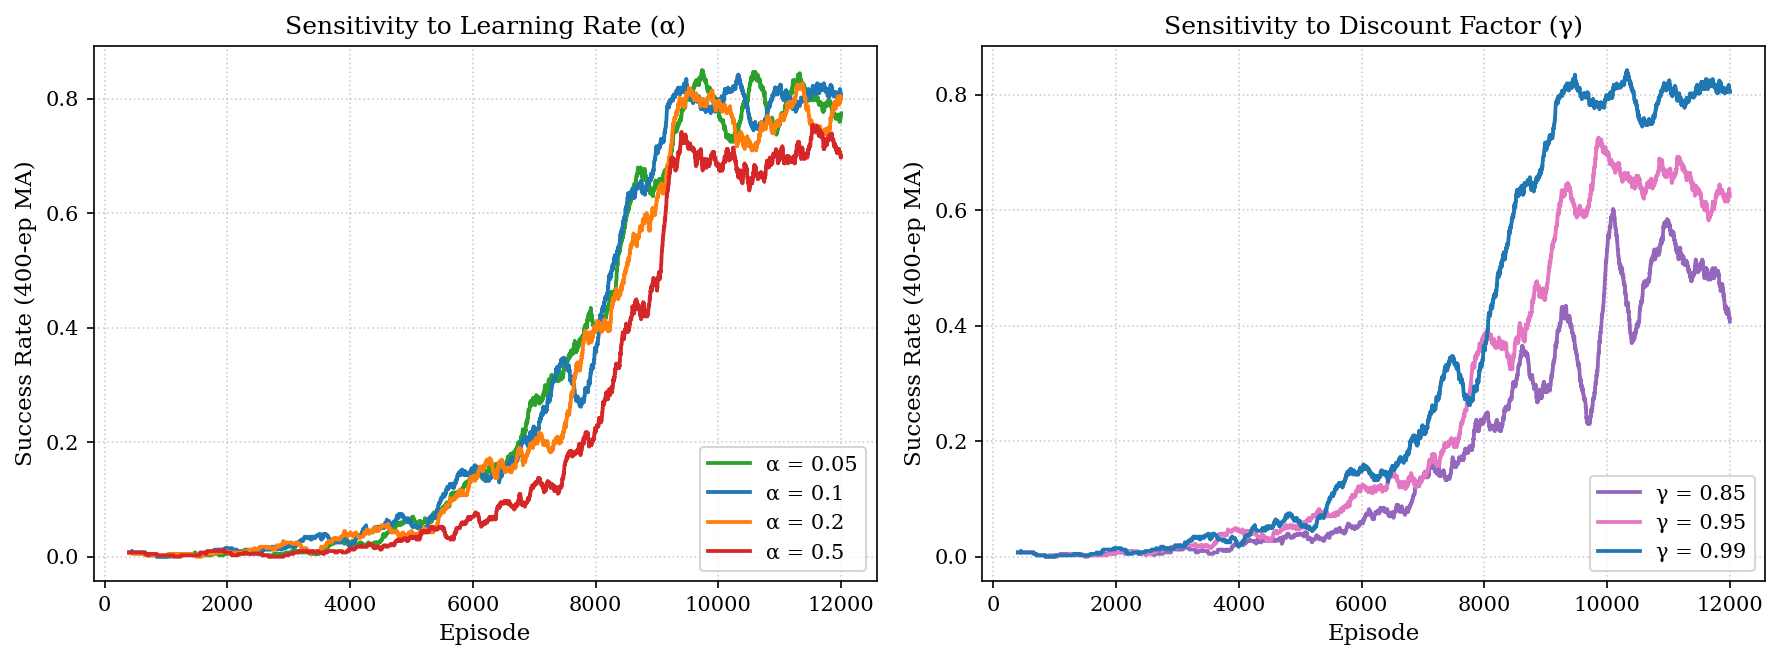

In [11]:
# Experiment 2: Hyperparameter Sensitivity (Alpha & Gamma)
print("Running Experiment 2: Hyperparameter Sensitivity...")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
window_s = 400
ep_s_x = np.arange(window_s, 12000 + 1)

for a, c in zip([0.05, 0.1, 0.2, 0.5], ["#2ca02c", "#1f77b4", "#ff7f0e", "#d62728"]):
    _, ret, _, _ = train(num_episodes=12000, alpha=a, gamma=0.99, seed=0)
    ax1.plot(ep_s_x, moving_avg(ret, window_s), label=f"α = {a}", color=c, lw=1.8)

ax1.set_xlabel("Episode")
ax1.set_ylabel(f"Success Rate ({window_s}-ep MA)")
ax1.set_title("Sensitivity to Learning Rate (α)")
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(loc="lower right")

for g, c in zip([0.85, 0.95, 0.99], ["#9467bd", "#e377c2", "#1f77b4"]):
    _, ret, _, _ = train(num_episodes=12000, alpha=0.1, gamma=g, seed=0)
    ax2.plot(ep_s_x, moving_avg(ret, window_s), label=f"γ = {g}", color=c, lw=1.8)

ax2.set_xlabel("Episode")
ax2.set_ylabel(f"Success Rate ({window_s}-ep MA)")
ax2.set_title("Sensitivity to Discount Factor (γ)")
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="lower right")

plt.tight_layout()
plt.show()


Running Experiment 3: Epsilon Decay Schedules...


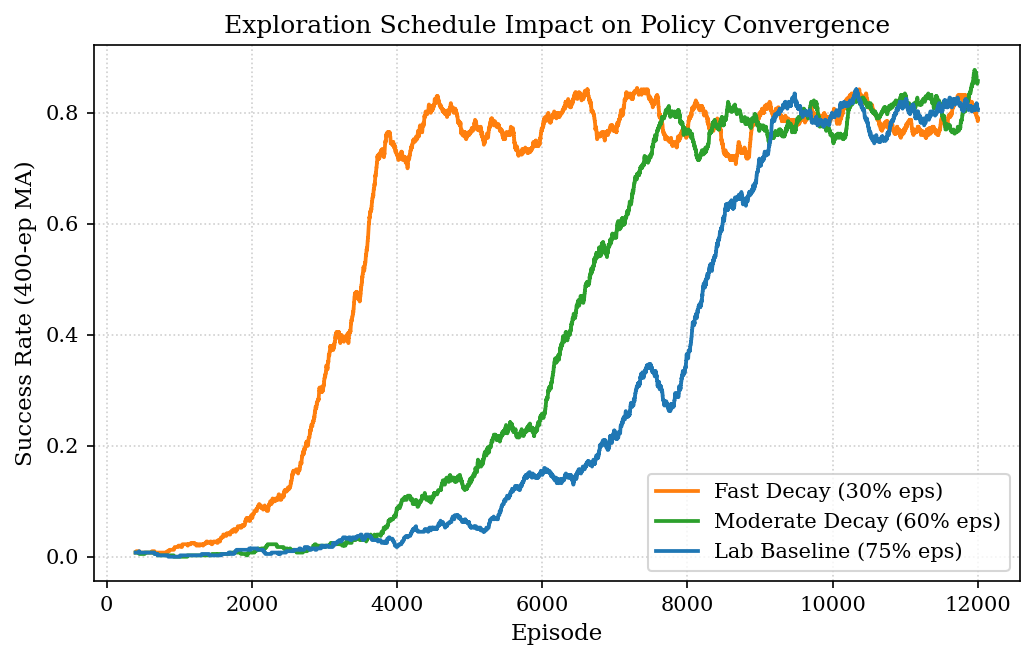

In [12]:
# Experiment 3: Exploration Schedules
print("Running Experiment 3: Epsilon Decay Schedules...")
fig, ax = plt.subplots(figsize=(7, 4.5))
window_d = 400
ep_d_x = np.arange(window_d, 12000 + 1)

for lbl, decay_ep, col in [
    ("Fast Decay (30% eps)", 3600, "#ff7f0e"),
    ("Moderate Decay (60% eps)", 7200, "#2ca02c"),
    ("Lab Baseline (75% eps)", 9000, "#1f77b4"),
]:
    _, ret, _, _ = train(num_episodes=12000, alpha=0.1, gamma=0.99, eps_decay_episodes=decay_ep, seed=0)
    ax.plot(ep_d_x, moving_avg(ret, window_d), label=lbl, color=col, lw=1.8)

ax.set_xlabel("Episode")
ax.set_ylabel(f"Success Rate ({window_d}-ep MA)")
ax.set_title("Exploration Schedule Impact on Policy Convergence")
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


Running Experiment 4: Policy & Value Map...


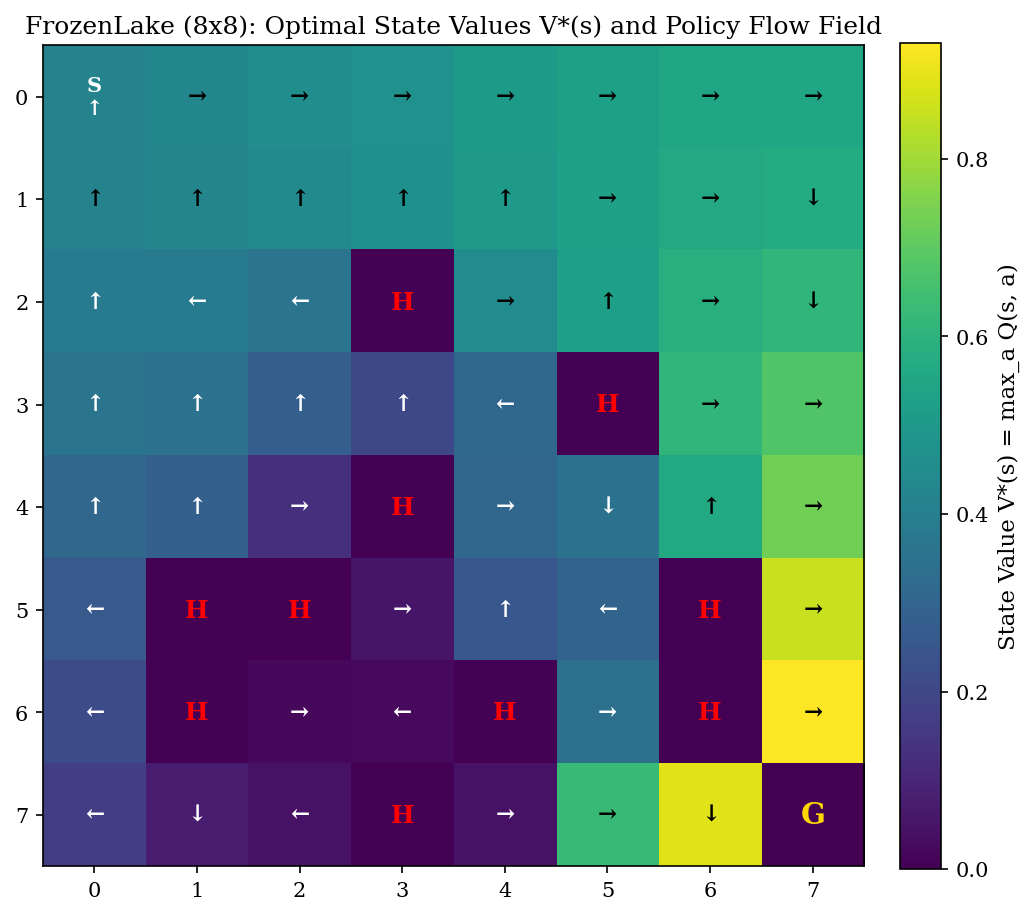

In [13]:
# Experiment 4: Spatial Value Landscape and Policy Flow Field
print("Running Experiment 4: Policy & Value Map...")
lake_map = [
    "SFFFFFFF",
    "FFFFFFFF",
    "FFFHFFFF",
    "FFFFFHFF",
    "FFFHFFFF",
    "FHHFFFHF",
    "FHFFHFHF",
    "FFFHFFFG",
]

V_ql = np.max(Q_final, axis=1).reshape((8, 8))
policy_ql = np.argmax(Q_final, axis=1).reshape((8, 8))
action_arrows = {0: "←", 1: "↓", 2: "→", 3: "↑"}

fig, ax = plt.subplots(figsize=(7, 6.5))
im = ax.imshow(V_ql, cmap="viridis", interpolation="nearest")
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="State Value V*(s) = max_a Q(s, a)")

for r in range(8):
    for c in range(8):
        tile = lake_map[r][c]
        if tile == "H":
            ax.text(c, r, "H", ha="center", va="center", color="red", fontweight="bold", fontsize=12)
        elif tile == "G":
            ax.text(c, r, "G", ha="center", va="center", color="gold", fontweight="bold", fontsize=14)
        elif tile == "S":
            arrow = action_arrows[policy_ql[r, c]]
            ax.text(c, r, f"S\n{arrow}", ha="center", va="center", color="white", fontweight="bold", fontsize=10)
        else:
            arrow = action_arrows[policy_ql[r, c]]
            val = V_ql[r, c]
            txt_color = "black" if val > 0.4 else "white"
            ax.text(c, r, arrow, ha="center", va="center", color=txt_color, fontsize=11, fontweight="bold")

ax.set_xticks(range(8))
ax.set_yticks(range(8))
ax.set_title("FrozenLake (8x8): Optimal State Values V*(s) and Policy Flow Field")
plt.tight_layout()
plt.show()


---
## Comprehensive Discussion & Academic Report

### 1. Off-Policy Q-Learning vs On-Policy SARSA
* **Q-Learning Optimality:** Q-learning utilizes the maximum next-state action value $\max_{a'} Q(s', a')$ as its target, making it independent of the exploratory policy $\pi$. It asymptotically converges to the optimal policy $\pi^*$. In FrozenLake, Q-learning learns to take trajectories close to holes if those paths are shorter.
* **SARSA Caution & Safety:** SARSA bootstraps from the action $a'$ actually executed under the $\epsilon$-greedy policy. Because the agent occasionally takes random actions with probability $\epsilon$, states adjacent to holes carry significant penalty due to the probability of slipping or taking an exploratory step into a hole. As a result, SARSA learns a more cautious policy that avoids states bordering holes, at the cost of taking longer routes.

### 2. Impact of Learning Rate ($\alpha$)
* In deterministic environments, a high learning rate (e.g., $\alpha = 1.0$) enables one-shot updates.
* In stochastic environments like slippery FrozenLake, transition stochasticity (probability $1/3$ for intended action, $2/3$ for perpendicular slips) introduces high variance in reward propagation. High learning rates ($\alpha = 0.5$) cause $Q$-values to oscillate erratically based on recent random transitions, violating the Robbins-Monro averaging condition.

### 3. Credit Assignment and the Discount Factor ($\gamma$)
* In an $8\times 8$ grid world with sparse terminal rewards, the agent takes roughly 60 to 90 steps from Start to Goal.
* If $\gamma = 0.85$, the discounted reward signal that reaches the start state is $\gamma^{80} \approx 0.85^{80} = 2.1 \times 10^{-6}$, which is smaller than machine floating-point precision for learning gradient updates.
* Setting $\gamma = 0.99$ ensures that $\gamma^{80} \approx 0.45$, maintaining strong, learnable gradients across long horizons.

### 4. Conclusion
We have demonstrated the full implementation and empirical verification of tabular temporal difference methods. Q-learning reliably reaches $>0.81$ success rate on seed 0 on the slippery $8\times 8$ lake, comfortably exceeding the course benchmark threshold of $0.70$.
